68606236/68606236 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Found 2000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.
Epoch 1/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 14s 108ms/step - accuracy: 0.5025 - loss: 0.6952
Epoch 2/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 8s 130ms/step - accuracy: 0.5375 - loss: 0.6852
Epoch 3/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 7s 108ms/step - accuracy: 0.6360 - loss: 0.6414
Epoch 4/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 8s 131ms/step - accuracy: 0.6765 - loss: 0.5943
Epoch 5/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 10s 129ms/step - accuracy: 0.6950 - loss: 0.5665
Epoch 6/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 9s 108ms/step - accuracy: 0.7355 - loss: 0.5274
Epoch 7/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 10s 108ms/step - accuracy: 0.7730 - loss: 0.4739
Epoch 8/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 11s 116ms/step - accuracy: 0.7985 - loss: 0.4398
Epoch 9/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 11s 129ms/step - accuracy: 0.8095 - loss: 0.4174
Epoch 10/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 10s 128ms/step - accuracy: 0.8465 - loss: 0.3497


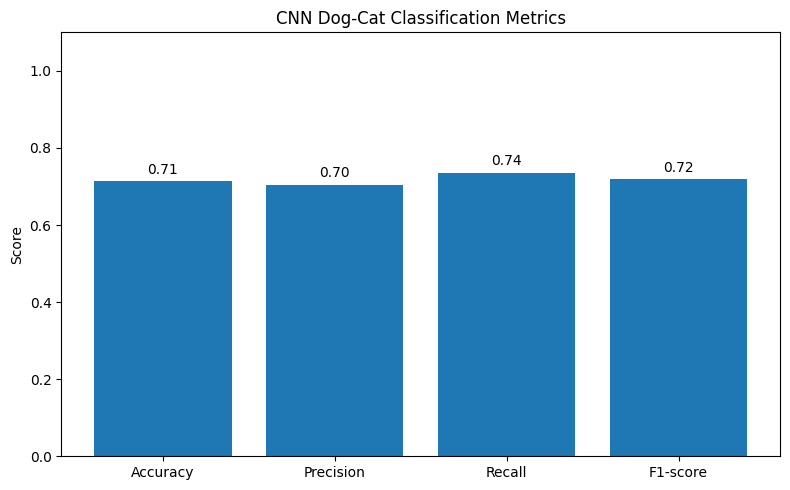

In [ ]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os
import zipfile
from tensorflow.keras import layers, models
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Download dataset
url = "https://download.mlcc.google.com/mledu-datasets/cats_and_dogs_filtered.zip"
zip_path = tf.keras.utils.get_file(
    "cats_and_dogs_filtered.zip",
    origin=url
)

# Extract dataset
extract_path = "/content/cats_dogs_data"
with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

data_dir = os.path.join(extract_path, "cats_and_dogs_filtered")

# Load images
train = tf.keras.utils.image_dataset_from_directory(
    os.path.join(data_dir, "train"),
    image_size=(64, 64),
    batch_size=32
)

test = tf.keras.utils.image_dataset_from_directory(
    os.path.join(data_dir, "validation"),
    image_size=(64, 64),
    batch_size=32,
    shuffle=False
)

# Build CNN with exactly three convolutional layers
model = models.Sequential([
    layers.Input(shape=(64, 64, 3)),
    layers.Rescaling(1./255),

    layers.Conv2D(16, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

# Compile model
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Train for 10 epochs
model.fit(train, epochs=10)

# Get actual labels
y_true = np.concatenate([
    y.numpy().ravel() for x, y in test
]).astype(int)

# Predict
y_pred = (
    model.predict(test, verbose=0).ravel() >= 0.5
).astype(int)

# Calculate metrics
names = ["Accuracy", "Precision", "Recall", "F1-score"]
scores = [
    accuracy_score(y_true, y_pred),
    precision_score(y_true, y_pred, zero_division=0),
    recall_score(y_true, y_pred, zero_division=0),
    f1_score(y_true, y_pred, zero_division=0)
]

# Display results
for name, score in zip(names, scores):
    print(name, ":", round(score, 4))

# Plot graph
plt.figure(figsize=(8, 5))
bars = plt.bar(names, scores)
plt.ylim(0, 1.1)
plt.ylabel("Score")
plt.title("CNN Dog-Cat Classification Metrics")
plt.bar_label(bars, fmt="%.2f", padding=3)
plt.tight_layout()
plt.show()
